In [468]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy
import random
import math

names = open ('names.txt', 'r').read().splitlines()

chars = sorted(list(set(''.join(names))))
stoi= {s:i+1 for i,s in enumerate(chars)} 
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
#print(itos)


In [469]:
n_embd = 2      
block_size = 3   
n_hidden = 100   

def dataset(names):

    
    x, y = [] , []

    for name in names:
        print(name)
        
        context = [0] * block_size
        for ch in name+ '.':
            ix= stoi[ch]
            x.append(context)
            y.append(ix)
            print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix]
            
            
    x = torch.tensor(x)
    y = torch.tensor(y)
    
    return x,y

random.seed(58)
random.shuffle(names)
n1=int(len(names)*0.8)
n2=int(len(names)*0.9)
n3=int(len(names))
xtr, ytr = dataset(names[:n1])
#xdev, ydev = dataset(names[n1:n2])
#xte, yte = dataset(names[n2:])




yago
... ---> y
..y ---> a
.ya ---> g
yag ---> o
ago ---> .
kharter
... ---> k
..k ---> h
.kh ---> a
kha ---> r
har ---> t
art ---> e
rte ---> r
ter ---> .
veya
... ---> v
..v ---> e
.ve ---> y
vey ---> a
eya ---> .
kahlaya
... ---> k
..k ---> a
.ka ---> h
kah ---> l
ahl ---> a
hla ---> y
lay ---> a
aya ---> .
bowdrie
... ---> b
..b ---> o
.bo ---> w
bow ---> d
owd ---> r
wdr ---> i
dri ---> e
rie ---> .
melrose
... ---> m
..m ---> e
.me ---> l
mel ---> r
elr ---> o
lro ---> s
ros ---> e
ose ---> .
sheena
... ---> s
..s ---> h
.sh ---> e
she ---> e
hee ---> n
een ---> a
ena ---> .
arna
... ---> a
..a ---> r
.ar ---> n
arn ---> a
rna ---> .
kailea
... ---> k
..k ---> a
.ka ---> i
kai ---> l
ail ---> e
ile ---> a
lea ---> .
bayan
... ---> b
..b ---> a
.ba ---> y
bay ---> a
aya ---> n
yan ---> .
aidric
... ---> a
..a ---> i
.ai ---> d
aid ---> r
idr ---> i
dri ---> c
ric ---> .
paetyn
... ---> p
..p ---> a
.pa ---> e
pae ---> t
aet ---> y
ety ---> n
tyn ---> .
samarah
... ---> s
..s ---> 

In [470]:
c = torch.randn((27,n_embd))
c.shape

torch.Size([27, 2])

In [471]:
emb= c[xtr]
emb.shape


torch.Size([182578, 3, 2])

In [472]:
w1 = torch.randn((n_embd * block_size, n_hidden)) #* (5/3) / ((n_embd * block_size) ** 0.5)
b1= torch.randn(n_hidden) #* 0.01
h = torch.tanh(emb.view(-1, n_embd * block_size) @ w1)
w2= torch.randn((n_hidden,27)) #*0.01
b2= torch.randn(27) #* 0

"""bngain = torch.ones((1, n_hidden))
bnbias = torch.zeros((1, n_hidden))

bnmean_running = torch.zeros((1, n_hidden))
bnstd_running = torch.ones((1, n_hidden))"""

parameters = [c,w1,w2,b2,]

h.shape

torch.Size([182578, 100])

In [473]:
logits = h @ w2 + b2
prob = logits.exp() / logits.exp().sum(1, keepdim=True) 
loss = -prob[torch.arange(xtr.shape[0]), ytr ].log().mean()




lre = torch.linspace(-3,0,1000)
lrs = 10**lre
lri , lossi = [],[]
step = []
loss

tensor(14.0761)

In [476]:
loss = F.cross_entropy(logits , yte)
loss

ValueError: Expected input batch_size (182578) to match target batch_size (8).

In [475]:
for p in parameters:
    p.requires_grad = True

for i in range(1000):
        
    ix = torch.randint(0, xtr.shape[0],(32,))
    emb= c[xte[ix]]
    #hpreact = (emb.view(-1, n_embd * block_size))@ w1  
    #bnmeani = hpreact.mean(0, keepdim=True)
    #bnstdi = hpreact.std(0, keepdim=True)
    #hpreact= bngain * (hpreact - bnmeani) / bnstdi + bnbias
    
    
    
    h = torch.tanh((emb.view(-1, n_embd * block_size))@ w1  )           #hpreact 
    logits = h @ w2 + b2
    loss = F.cross_entropy(logits , yte[ix])
    
    #with torch.no_grad():
        #bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        #bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
    
    
    for p in parameters:
        p.grad = None
    
    loss.backward()

    #lr = lrs[i]
    #lr = 0.1 if i < 100000 else 0.01
    lr=1
    for p in parameters:
        p.data += lr * -p.grad
        
    if i %10000 == 0:
        print(f'{i:7d}: {loss.item():.4f}') 
        
    step.append(i)    
    lri.append(lre[i])
    lossi.append(loss.log10().item())
    
    
plt.figure(figsize=(20, 4))
plt.hist(h.view(-1).tolist(), 50)
    
plt.figure(figsize=(20, 10))
plt.imshow(h.abs() > 0.99, cmap='gray', interpolation='nearest')
    
    
    

#print(loss.item())



IndexError: index 172371 is out of bounds for dimension 0 with size 8

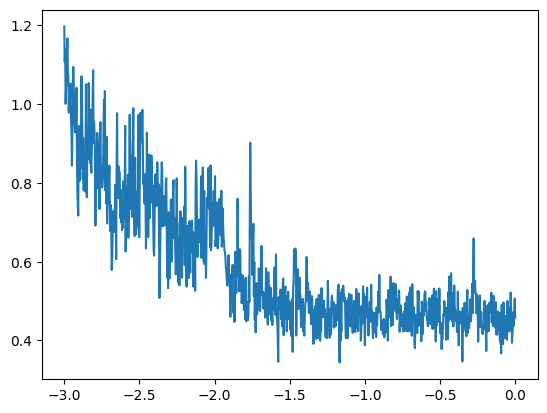

In [ ]:
plt.plot(lri,lossi)
#plt.plot(step, lossi)


In [ ]:

emb= c[xdev]
hpreact = emb.view(-1, n_embd * block_size) @ w1
hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
h = torch.tanh(hpreact)
logits = h @ w2 + b2
loss = F.cross_entropy(logits , ydev)
loss


tensor(5.1255, grad_fn=<NllLossBackward0>)

In [ ]:
emb= c[xtr]
hpreact = emb.view(-1, n_embd * block_size) @ w1
hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
h = torch.tanh(hpreact)
logits = h @ w2 + b2
loss = F.cross_entropy(logits , ytr)
loss

tensor(5.5300, grad_fn=<NllLossBackward0>)

In [ ]:
emb = c[xte] # (32, 3, 2)
hpreact = emb.view(-1, n_embd * block_size) @ w1 
hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
h = torch.tanh(hpreact)
logits = h @ w2 + b2 # (32, 27)
loss = F.cross_entropy(logits, yte)
loss


tensor(4.6596, grad_fn=<NllLossBackward0>)

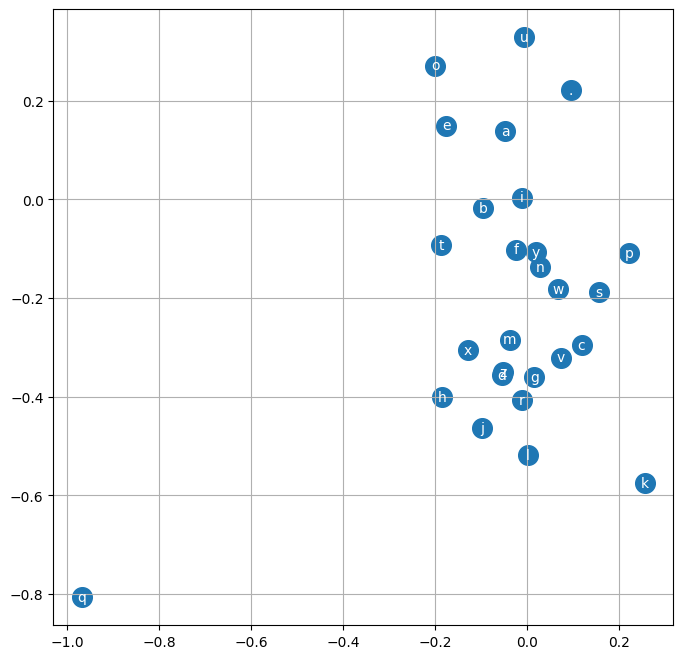

In [ ]:
plt.figure(figsize=(8,8))
plt.scatter(c[:,0].data, c[:,1].data, s=200)
for i in range(c.shape[0]):
    plt.text(c[i,0].item(), c[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [ ]:
g = torch.Generator().manual_seed(2147483647 + 100)

for _ in range(20):
    
    out = []
    context = [0] * block_size 
    while True:
      emb = c[torch.tensor([context])] 
      hpreact = emb.view(-1, n_embd * block_size) @ w1
      hpreact = bngain * (hpreact - bnmean_running) / bnstd_running + bnbias
      h = torch.tanh(hpreact)
      logits = h @ w2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

ttthttttttteytytyttthttttttyttttttttjttetttttt.
tattattfttttetytttfytftttatttttftttttttttttttyttfttttyktttttttttttttttttwtttuyttetttttyttattttnttttytttttttyyttntttmyttttyttyttattttttttttftyttthytntttttttttyktttttttytytttttttyhttattapttttttttttttittttttttytfttayttftfttttttkthykei.
ttttttttftytttttttttjtttttttpftttyttttfytfttyttttttttttttttsttttyatttthtttyttttttttttttttttittftytttyhyttttttttttttttyttttttttttttttttttttytttttttttttutttytta.
tttttttteatttfttttttykttttttlttttttttttttttittttttttttytthtyttstthttttttttttytttttttteytwtttttthttttatttttatttttpyfytyttttttttytatttattttthttttttyttatttqttttttaftttt.
ttttttttttttetttttttfttttttttttyttttttttttttttthtthttttyttttttfi.
ttttttyttttttttytttttttttttttetthttttttttetttttkuyttatttttttttttyetttthtttttttettyta.
ttttttjttyatyftttytyttttttytthtatttttathtttttttttytttttttttttttettayttytttttttyttttttttttttttttttttftttttttttfttttttttttttttttatttttttftettttttttyttttttytttttttvtttt.
ttttktthtttttttytttytttttfttttyyyttttttttttttttthttttthttttk.
ttttttttttt